# **Documento elegido:** *Encuesta Nacional a Grandes Empresas 2016*, publicada por el
# Instituto Nacional de Estadística y Censos (INDEC), Argentina.
#
# **Por qué lo elegí:** está en español, es público, tiene texto extraíble (no es un
# escaneo) y contiene tablas de datos y páginas de texto narrativo, que son lo que
# necesito para las consignas 3 y 4.
#
# **Fuente:** INDEC. (2018). *Encuesta Nacional a Grandes Empresas 2016*.
# https://www.indec.gob.ar/uploads/informesdeprensa/enge_01_18.pdf
#
# ## 1) Adquisición y metadatos
# ### 1.1 Instalación e importación de librerías
# - `requests`: para descargar el archivo desde internet.
# - `PyMuPDF`: para abrir el PDF, leer sus metadatos y extraer su texto.
# - `pdfplumber`: para extraer tablas (se usa en la consigna 3).
# - `pandas`: para mostrar los datos en tablas.

In [2]:
!pip install pymupdf pdfplumber --quiet

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.7/43.7 kB 2.1 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.4/62.4 kB 4.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 25.8/25.8 MB 79.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.0/60.0 kB 3.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.6/6.6 MB 115.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.1/7.1 MB 104.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.8/3.8 MB 105.9 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.29.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.


In [3]:
import requests
import pymupdf
import pdfplumber
import pandas as pd

# ###  Descarga del PDF con `requests`
# Se hace una petición GET a la URL y se guarda el contenido en un archivo local en
# modo binario (`"wb"`), porque un PDF no es texto plano. Antes de guardarlo se
# verifica que la descarga haya sido exitosa y que realmente sea un PDF (y no, por
# ejemplo, una página HTML de error).

In [4]:
URL_PDF = "https://www.indec.gob.ar/uploads/informesdeprensa/enge_01_18.pdf"
ARCHIVO_PDF = "enge_2016_indec.pdf"  # nombre con el que se guarda en Colab

# Algunos servidores rechazan peticiones sin "User-Agent", por eso se lo incluye
encabezados = {"User-Agent": "Mozilla/5.0"}

respuesta = requests.get(URL_PDF, headers=encabezados, timeout=60)

print("Código de estado HTTP:", respuesta.status_code)  # 200 = descarga exitosa
print("Tipo de contenido    :", respuesta.headers.get("Content-Type"))
print("Tamaño descargado    :", round(len(respuesta.content) / 1024), "KB")

# Si el servidor respondió con un error (404, 403, etc.), se detiene con un mensaje
respuesta.raise_for_status()

# Todo PDF válido empieza con los bytes "%PDF": se usa para confirmar el formato
if not respuesta.content.startswith(b"%PDF"):
    raise ValueError("El archivo descargado no parece ser un PDF válido")

# Guardar el contenido en un archivo local (modo binario)
with open(ARCHIVO_PDF, "wb") as archivo:
    archivo.write(respuesta.content)

print(f"\nArchivo guardado como '{ARCHIVO_PDF}'")

Código de estado HTTP: 200
Tipo de contenido    : application/pdf
Tamaño descargado    : 1933 KB

Archivo guardado como 'enge_2016_indec.pdf'


# ### Inspección: metadatos del archivo
# PyMuPDF guarda los metadatos en el diccionario `doc.metadata`. El número de páginas
# se obtiene con `doc.page_count`.
#
# El **software de creación** se reparte en dos campos:
# - `creator`: el programa con el que se armó el documento original.
# - `producer`: el programa que generó el archivo PDF final.

In [5]:
doc = pymupdf.open(ARCHIVO_PDF)  # abrir el PDF
meta = doc.metadata              # diccionario con los metadatos


def valor(campo):
    """Devuelve el valor del metadato o un aviso si está vacío."""
    return campo if campo else "(no informado en los metadatos)"


print("METADATOS DEL PDF")
print("-" * 60)
print("Título             :", valor(meta.get("title")))
print("Autor              :", valor(meta.get("author")))
print("Número de páginas  :", doc.page_count)
print("Software (creator) :", valor(meta.get("creator")))
print("Software (producer):", valor(meta.get("producer")))
print("Fecha de creación  :", valor(meta.get("creationDate")))
print("Formato            :", valor(meta.get("format")))

METADATOS DEL PDF
------------------------------------------------------------
Título             : (no informado en los metadatos)
Autor              : (no informado en los metadatos)
Número de páginas  : 75
Software (creator) : Adobe InDesign CC 13.0 (Windows)
Software (producer): Adobe PDF Library 15.0
Fecha de creación  : D:20180105161738-03'00'
Formato            : PDF 1.4


# ### Título y autor tomados de la portada
# En este PDF los metadatos de **título** y **autor** están vacíos, algo frecuente en
# documentos maquetados con Adobe InDesign. Para completar la información, se lee el
# texto de la primera página (la portada) y se toman de allí el título y la institución
# autora. Estos datos provienen del **contenido** del documento, no de sus metadatos.

In [6]:
texto_portada = doc[0].get_text()
lineas = [linea.strip() for linea in texto_portada.splitlines() if linea.strip()]

print("Primeras líneas de la portada:")
for linea in lineas[:10]:
    print("  ", linea)

Primeras líneas de la portada:
   Encuesta Nacional a
   Grandes Empresas /2016
   ISBN: 978-950-896-500-4


In [7]:
titulo_portada = "Encuesta Nacional a Grandes Empresas 2016"
autor_portada = "Instituto Nacional de Estadística y Censos (INDEC)"

resumen = pd.DataFrame(
    [
        ["Título", meta.get("title") or titulo_portada,
         "Metadatos" if meta.get("title") else "Portada del documento"],
        ["Autor", meta.get("author") or autor_portada,
         "Metadatos" if meta.get("author") else "Portada del documento"],
        ["Número de páginas", doc.page_count, "Metadatos / PyMuPDF"],
        ["Software de creación (creator)", valor(meta.get("creator")), "Metadatos"],
        ["Software de generación del PDF (producer)", valor(meta.get("producer")), "Metadatos"],
    ],
    columns=["Campo", "Valor", "Origen del dato"],
)
resumen

,Campo,Valor,Origen del dato
0,Título,Encuesta Nacional a Grandes Empresas 2016,Portada del documento
1,Autor,Instituto Nacional de Estadística y Censos (IN...,Portada del documento
2,Número de páginas,75,Metadatos / PyMuPDF
3,Software de creación (creator),Adobe InDesign CC 13.0 (Windows),Metadatos
4,Software de generación del PDF (producer),Adobe PDF Library 15.0,Metadatos


# ## Análisis estructural del texto
# ### Extracción cruda del texto
#
# **Función utilizada:** `page.get_text()` de PyMuPDF (equivale a `get_text("text")`).
# Devuelve el texto de una página como un único *string*, tal como está almacenado en el
# PDF, sin limpiarlo ni reordenarlo.
#
# **Cómo ver el texto lo más crudo posible:** si se muestra con `print()`, los saltos de
# línea se "ejecutan" y el texto parece normal. En cambio, con `repr()` se muestra el
# string con todos sus caracteres de control escritos explícitamente (`\n`, `\t`, `\x0c`,
# etc.), que es lo que permite ver cómo están separadas realmente las líneas.

In [8]:
import re
import unicodedata
from collections import Counter

# Se reabre el PDF por si esta celda se ejecuta de forma independiente
doc = pymupdf.open(ARCHIVO_PDF)

# Página de texto narrativo, contando desde 1 (en PyMuPDF el índice empieza en 0)
PAGINA_EJEMPLO = 60
pagina = doc[PAGINA_EJEMPLO - 1]

# Extracción del texto de la página
texto_pagina = pagina.get_text()
print(f"Página {PAGINA_EJEMPLO}: {len(texto_pagina)} caracteres")

Página 60: 3381 caracteres


In [9]:
print("=== Con print(): así se ve el texto ===")
print(texto_pagina[:600])

print("\n=== Con repr(): así es realmente el string (primeros 600 caracteres) ===")
print(repr(texto_pagina[:600]))

=== Con print(): así se ve el texto ===
60
Indicadores de liquidez: estos indicadores surgen de la necesidad de medir la capa- 
cidad que tienen las empresas para cancelar sus obligaciones de corto plazo. Sirven 
para establecer la facilidad o dificultad que presenta una compañía para pagar sus 
pasivos corrientes al convertir a efectivo sus activos corrientes. Se trata de determinar 
qué pasaría si a la empresa se le exigiera el pago inmediato de todas sus obligaciones 
en el lapso inferior a un año. De esta forma, los índices de liquidez aplicados en un 
momento determinado permiten que se evalúe a la empresa desde el punto de vis

=== Con repr(): así es realmente el string (primeros 600 caracteres) ===
'60\nIndicadores de liquidez: estos indicadores surgen de la necesidad de medir la capa- \ncidad que tienen las empresas para cancelar sus obligaciones de corto plazo. Sirven \npara establecer la facilidad o dificultad que presenta una compañía para pagar sus \npasivos corrientes al c

In [10]:
textos_por_pagina = [p.get_text() for p in doc]
texto_completo = "".join(textos_por_pagina)

print("Páginas             :", len(textos_por_pagina))
print("Caracteres en total :", len(texto_completo))

Páginas             : 75
Caracteres en total : 131007


# ### Identificación de caracteres especiales
# Se cuentan los caracteres que pueden funcionar como separadores o que aparecen de
# forma "invisible" en el texto extraído.

In [11]:
buscados = {
    "\\n  (salto de línea)": "\n",
    "\\r  (retorno de carro)": "\r",
    "\\t  (tabulación)": "\t",
    "\\x0c (salto de página)": "\x0c",
    "\\xa0 (espacio de no separación)": "\xa0",
    "\\xad (guion blando)": "\xad",
    "\\u200b (espacio de ancho cero)": "\u200b",
}

filas = [[nombre, texto_completo.count(caracter)] for nombre, caracter in buscados.items()]

# Secuencias que se arman combinando caracteres
filas.append(["\\n\\n (línea en blanco, salto doble)", texto_completo.count("\n\n")])
filas.append(["Secuencias de 2 o más espacios seguidos", len(re.findall(r" {2,}", texto_completo))])
filas.append(["Palabra cortada con guion al final de línea (-\\n)", len(re.findall(r"\w-\n\w", texto_completo))])

tabla_separadores = pd.DataFrame(filas, columns=["Carácter o secuencia", "Cantidad"])
tabla_separadores

,Carácter o secuencia,Cantidad
0,\n (salto de línea),7416
1,\r (retorno de carro),0
2,\t (tabulación),190
3,\x0c (salto de página),0
4,\xa0 (espacio de no separación),0
5,\xad (guion blando),109
6,\u200b (espacio de ancho cero),0
7,"\n\n (línea en blanco, salto doble)",0
8,Secuencias de 2 o más espacios seguidos,506
9,Palabra cortada con guion al final de línea (-\n),7


In [12]:
permitidos = set("abcdefghijklmnopqrstuvwxyzáéíóúüñABCDEFGHIJKLMNOPQRSTUVWXYZÁÉÍÓÚÜÑ"
                 "0123456789 \n.,;:()[]%-–—/¿?¡!\"'$=+*<>°ª")
raros = Counter(c for c in texto_completo if c not in permitidos)

print("Caracteres poco comunes (los 15 más frecuentes):")
for caracter, cantidad in raros.most_common(15):
    nombre = unicodedata.name(caracter, "(sin nombre)")
    print(f"  {repr(caracter):10} U+{ord(caracter):04X}  {cantidad:6} veces  {nombre}")

Caracteres poco comunes (los 15 más frecuentes):
  '\t'       U+0009     190 veces  (sin nombre)
  '\xad'     U+00AD     109 veces  SOFT HYPHEN
  'º'        U+00BA       4 veces  MASCULINE ORDINAL INDICATOR
  '@'        U+0040       2 veces  COMMERCIAL AT
  '“'        U+201C       2 veces  LEFT DOUBLE QUOTATION MARK
  '”'        U+201D       2 veces  RIGHT DOUBLE QUOTATION MARK
  '©'        U+00A9       1 veces  COPYRIGHT SIGN


# ### Cómo se separan líneas, párrafos y secciones
# Se analiza cómo se ven estas separaciones en el texto crudo: primero las líneas,
# luego los bloques que detecta PyMuPDF y por último los títulos de secciones.

In [13]:
lineas = texto_pagina.split("\n")
print(f"La página {PAGINA_EJEMPLO} se divide en {len(lineas)} 'líneas' al cortar por \\n\n")

print("Primeras 15 líneas (con su largo):")
for i, linea in enumerate(lineas[:15]):
    print(f"{i:2} | {len(linea):3} caracteres | {repr(linea)}")

# Estadísticas del largo de las líneas (una línea muy corta suele ser el fin de un párrafo o un título)
pd.Series([len(l) for l in lineas if l.strip()]).describe().round(1)

La página 60 se divide en 45 'líneas' al cortar por \n

Primeras 15 líneas (con su largo):
 0 |   2 caracteres | '60'
 1 |  84 caracteres | 'Indicadores de liquidez: estos indicadores surgen de la necesidad de medir la capa- '
 2 |  84 caracteres | 'cidad que tienen las empresas para cancelar sus obligaciones de corto plazo. Sirven '
 3 |  83 caracteres | 'para establecer la facilidad o dificultad que presenta una compañía para pagar sus '
 4 |  90 caracteres | 'pasivos corrientes al convertir a efectivo sus activos corrientes. Se trata de determinar '
 5 |  87 caracteres | 'qué pasaría si a la empresa se le exigiera el pago inmediato de todas sus obligaciones '
 6 |  86 caracteres | 'en el lapso inferior a un año. De esta forma, los índices de liquidez aplicados en un '
 7 |  80 caracteres | 'momento determinado permiten que se evalúe a la empresa desde el punto de vista '
 8 |  69 caracteres | 'del pago inmediato de sus acreencias corrientes, en caso excepcional.'
 9 |  82 caracteres

,0
count,44.0
mean,75.8
std,21.8
min,2.0
25%,80.0
50%,83.0
75%,86.0
max,93.0


In [14]:
bloques = pagina.get_text("blocks")
print(f"PyMuPDF detecta {len(bloques)} bloques en la página {PAGINA_EJEMPLO}\n")

for b in bloques[:5]:
    print(f"Bloque {b[5]} (posición vertical: {round(b[1])}-{round(b[3])})")
    print("  ", repr(b[4][:150]))

PyMuPDF detecta 9 bloques en la página 60

Bloque 0 (posición vertical: 703-715)
   '60\n'
Bloque 1 (posición vertical: 63-157)
   'Indicadores de liquidez: estos indicadores surgen de la necesidad de medir la capa- \ncidad que tienen las empresas para cancelar sus obligaciones de c'
Bloque 2 (posición vertical: 171-229)
   'Liquidez corriente: indica la capacidad que tiene la empresa para cumplir con sus \nobligaciones financieras, deudas o pasivos a corto plazo. Al dividi'
Bloque 3 (posición vertical: 243-289)
   'Indicadores de solvencia: estos indicadores tienen por objeto medir en qué grado y \nde qué forma participan los acreedores dentro del financiamiento d'
Bloque 4 (posición vertical: 303-373)
   'Endeudamiento del activo / Autonomía: este índice permite determinar el nivel de \nautonomía financiera. Cuando el índice es elevado indica que la empr'


In [15]:
patron_titulo = re.compile(r"^(\d+(\.\d+)*\.?|Cuadro\s+\d+(\.\d+)?)\s+\S")

encontrados = []
for n_pagina, texto in enumerate(textos_por_pagina, start=1):
    for linea in texto.split("\n"):
        if patron_titulo.match(linea.strip()) and len(linea.strip()) < 100:
            encontrados.append((n_pagina, linea.strip()))

print(f"Líneas que parecen títulos de secciones o cuadros: {len(encontrados)}\n")
for n_pagina, linea in encontrados[:25]:
    print(f"Página {n_pagina:2} | {repr(linea)}")

Líneas que parecen títulos de secciones o cuadros: 347

Página  2 | '1. Empresas. 2. Estadísticas. I. Título.'
Página  3 | '1. Caracterización del panel de grandes empresas..................................................5'
Página  3 | '1.2 Empresas comunes en los períodos considerados.............................................6'
Página  3 | '1.4 Participación de las grandes empresas en la economía nacional.......................9'
Página  3 | '2.1 Agregados macroeconómicos para el total del panel.......................................12'
Página  3 | '2.5 Indicadores económico-financieros para el total del panel...............................32'
Página  3 | '3. Resultados por sector de actividad económica principal..................................34'
Página  3 | '3.1 Agregados macroeconómicos por sector de actividad económica principal....35'
Página  3 | '3.2 Origen del capital por sector de actividad económica principal........................37'
Página  3 | '3.3 Utilidad por sect

# ## Extracción de datos tabulares
# ### Primer intento: `extract_tables()` en la página 19
# La búsqueda automática de tablas (que se basa en las líneas dibujadas en la página)
# marcó como candidata una tabla de 19 filas y 25 columnas en la página 19. Antes de usarla se revisa qué contiene realmente esa página.

In [16]:
import re
import numpy as np

with pdfplumber.open(ARCHIVO_PDF) as pdf:
    pagina_19 = pdf.pages[18]

    print("=== Texto de la página 19 (primeras líneas) ===")
    print("\n".join(pagina_19.extract_text().split("\n")[:8]))

    print("\n=== Primeras filas de la 'tabla' de 19 filas x 25 columnas ===")
    tabla_p19 = pagina_19.extract_tables()[0]
    for fila in tabla_p19[:6]:
        print(fila)

=== Texto de la página 19 (primeras líneas) ===
Gráfico 4.1 Empresas exportadoras e importadoras y saldo comercial.
Años 2012-2016
2012 2013 2014 2015 2016
Unidades
Empresas
que 347 347 338 339 325
exportan
Empresas

=== Primeras filas de la 'tabla' de 19 filas x 25 columnas ===
['', '', None, None, None, '', None, None, None, None, 'Unidades', None, None, None, None, '', None, None, None, None, '', None, None, None, None]
[None, '347\n422', None, None, None, '347\n432', None, None, None, None, '338\n438', None, None, None, None, '339\n424', None, None, None, None, '325\n420', None, None, None, None]
['', 'Exporta', None, None, None, 'ción', None, None, None, None, 'Importación', None, None, None, None, 'Sal', None, None, None, None, 'do comercial', None, None, None, None]
[None, '', None, None, None, '', None, None, None, None, '', None, None, None, None, '', None, None, None, None, '', None, None, None, None]
['700.000', '', None, None, None, '', None, None, None, None, 'Millones de 

# ### Conclusión del diagnóstico
# *(Completar según lo que se vea arriba.)* Si el texto de la página comienza con
# "Gráfico 4.1" y las filas de la "tabla" están casi vacías (`''`, `None`), significa que
# `pdfplumber` detectó las **líneas de la cuadrícula de un gráfico** y no una tabla de
# datos. Los datos de esa página están en el gráfico, no en una tabla.
#
# ### 3.2 Segundo intento: buscar un cuadro de datos real
# Los cuadros estadísticos de este informe no tienen líneas dibujadas, por eso la
# detección por líneas falla. Se usa otra estrategia: localizar la página del cuadro
# por su título y reconstruir la tabla a partir del **texto de cada línea**
# (`page.extract_text()`), separando la etiqueta de la fila de sus valores numéricos.
#
# **Cuadro elegido:** Cuadro 6.2, "Activo, pasivo y patrimonio neto. Años 2012-2016".

In [17]:
def buscar_paginas(ruta_pdf, texto):
    """Devuelve los números de página (desde 1) cuyo texto contiene 'texto'."""
    encontradas = []
    with pdfplumber.open(ruta_pdf) as pdf:
        for n_pagina, pagina in enumerate(pdf.pages, start=1):
            if texto in (pagina.extract_text() or ""):
                encontradas.append(n_pagina)
    return encontradas


TITULO_CUADRO = "Cuadro 6.2"
paginas = buscar_paginas(ARCHIVO_PDF, TITULO_CUADRO)
print(f"'{TITULO_CUADRO}' aparece en las páginas: {paginas}")

# La primera aparición es el cuadro; las siguientes pueden ser el índice de cuadros
PAGINA_TABLA = paginas[0]
print("Página elegida:", PAGINA_TABLA)

'Cuadro 6.2' aparece en las páginas: [20, 62]
Página elegida: 20


In [18]:
with pdfplumber.open(ARCHIVO_PDF) as pdf:
    texto_pagina = pdf.pages[PAGINA_TABLA - 1].extract_text()

lineas = texto_pagina.split("\n")

# Se toman las líneas desde el título del cuadro hasta la línea que dice "Fuente:"
inicio = next(i for i, l in enumerate(lineas) if TITULO_CUADRO in l)
fin = next(i for i, l in enumerate(lineas) if i > inicio and l.startswith("Fuente:"))
lineas_cuadro = lineas[inicio:fin]

print("Líneas del cuadro (en crudo):")
for linea in lineas_cuadro:
    print(repr(linea))

Líneas del cuadro (en crudo):
'Cuadro 6.2 Activo, pasivo y patrimonio neto.'
'Años 2012-2016'
'Año'
'Componente'
'2012 2013 2014 2015 2016'
'Millones de pesos'
'Activo total 1.003.901 1.295.325 1.730.999 2.503.287 2.990.480'
'Activo corriente 458.908 593.751 769.566 1.158.469 1.353.119'
'Activo no corriente 544.993 701.574 961.433 1.344.818 1.637.360'
'Pasivo total 571.296 739.402 987.387 1.489.561 1.719.190'
'Pasivo corriente 398.363 512.621 682.113 1.044.097 1.220.909'
'Pasivo no corriente 172.933 226.781 305.275 445.464 498.282'
'Patrimonio neto 432.605 555.923 743.611 1.013.726 1.271.289'


In [19]:
PATRON_NUMERO = re.compile(r"^[-–−]?\d{1,3}(\.\d{3})*(,\d+)?$")
N_ANIOS = 5  # el cuadro tiene 5 columnas de años (2012 a 2016)

anios = None
filas = []

for linea in lineas_cuadro:
    palabras = linea.split()

    # Fila de encabezado: termina con 5 años consecutivos (ej: 2012 2013 2014 2015 2016)
    if anios is None and len(palabras) >= N_ANIOS and all(
        re.fullmatch(r"20\d\d", p) for p in palabras[-N_ANIOS:]
    ):
        anios = palabras[-N_ANIOS:]
        continue

    # Fila de datos: la etiqueta seguida de 5 valores numéricos
    if len(palabras) > N_ANIOS and all(PATRON_NUMERO.match(p) for p in palabras[-N_ANIOS:]):
        etiqueta = " ".join(palabras[:-N_ANIOS])
        filas.append([etiqueta] + palabras[-N_ANIOS:])

print("Años detectados:", anios)
print("Filas de datos detectadas:", len(filas))

Años detectados: ['2012', '2013', '2014', '2015', '2016']
Filas de datos detectadas: 7


In [20]:
df_crudo = pd.DataFrame(filas, columns=["Componente"] + anios)
print("DataFrame con los valores todavía como texto:")
df_crudo

DataFrame con los valores todavía como texto:


,Componente,2012,2013,2014,2015,2016
0,Activo total,1.003.901,1.295.325,1.730.999,2.503.287,2.990.480
1,Activo corriente,458.908,593.751,769.566,1.158.469,1.353.119
2,Activo no corriente,544.993,701.574,961.433,1.344.818,1.637.360
3,Pasivo total,571.296,739.402,987.387,1.489.561,1.719.190
4,Pasivo corriente,398.363,512.621,682.113,1.044.097,1.220.909
5,Pasivo no corriente,172.933,226.781,305.275,445.464,498.282
6,Patrimonio neto,432.605,555.923,743.611,1.013.726,1.271.289


# ### Limpieza básica de la tabla
# 1. Nombres de columnas: "Componente" y un año por columna (ya asignados al crear el DataFrame).
# 2. Eliminar filas vacías o duplicadas.
# 3. Quitar espacios sobrantes en las etiquetas.
# 4. Convertir los números de texto (formato argentino) a valores numéricos.

In [21]:
def a_numero(texto):
    """Convierte '1.003.901' o '12,5' o '–9.062' en número. Si no se puede, NaN."""
    if pd.isna(texto):
        return np.nan
    t = str(texto).replace(" ", "").replace("−", "-").replace("–", "-")
    if "," in t:                         # decimal con coma: 1.234,5 -> 1234.5
        t = t.replace(".", "").replace(",", ".")
    else:                                # solo puntos de miles: 1.003.901 -> 1003901
        t = t.replace(".", "")
    try:
        return float(t)
    except ValueError:
        return np.nan


df = df_crudo.copy()

# Etiquetas sin espacios sobrantes
df["Componente"] = df["Componente"].str.strip()

# Eliminar filas vacías (sin etiqueta) y filas repetidas
df = df.replace("", np.nan).dropna(how="all").drop_duplicates().reset_index(drop=True)

# Convertir las columnas de años a números
for anio in anios:
    df[anio] = df[anio].map(a_numero)

print("Tipos de datos:")
print(df.dtypes)

df_final = df.copy()
df_final

Tipos de datos:
Componente     object
2012          float64
2013          float64
2014          float64
2015          float64
2016          float64
dtype: object


,Componente,2012,2013,2014,2015,2016
0,Activo total,1003901.0,1295325.0,1730999.0,2503287.0,2990480.0
1,Activo corriente,458908.0,593751.0,769566.0,1158469.0,1353119.0
2,Activo no corriente,544993.0,701574.0,961433.0,1344818.0,1637360.0
3,Pasivo total,571296.0,739402.0,987387.0,1489561.0,1719190.0
4,Pasivo corriente,398363.0,512621.0,682113.0,1044097.0,1220909.0
5,Pasivo no corriente,172933.0,226781.0,305275.0,445464.0,498282.0
6,Patrimonio neto,432605.0,555923.0,743611.0,1013726.0,1271289.0


In [22]:
datos = df_final.set_index("Componente")
diferencia = datos.loc["Activo total"] - (datos.loc["Pasivo total"] + datos.loc["Patrimonio neto"])
# Pueden aparecer diferencias de ±1 millón por redondeo de las cifras publicadas
print("Activo total - (Pasivo total + Patrimonio neto), por año (debería ser ~0):")
print(diferencia)

Activo total - (Pasivo total + Patrimonio neto), por año (debería ser ~0):
2012    0.0
2013    0.0
2014    1.0
2015    0.0
2016    1.0
dtype: float64


# ## Análisis de frecuencias (NLP básico)
# Se trabaja con la **página 60** del documento, que contiene únicamente texto narrativo
# (definiciones de los indicadores de liquidez, solvencia y rentabilidad). Se usa la biblioteca **NLTK** para:
# 1. **Tokenizar** el texto y convertirlo a minúsculas.
# 2. **Limpiar:** eliminar stop words y signos de puntuación.
# 3. **Visualizar** las 15 palabras más frecuentes en un gráfico de barras.

In [23]:
import re
from collections import Counter

import nltk
import matplotlib.pyplot as plt
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords

# Recursos que necesita NLTK:
# - punkt / punkt_tab: modelos para dividir el texto en oraciones y palabras
# - stopwords: listas de palabras funcionales por idioma
nltk.download("punkt", quiet=True)
nltk.download("punkt_tab", quiet=True)
nltk.download("stopwords", quiet=True)

True

In [29]:
doc = pymupdf.open(ARCHIVO_PDF)

PAGINA_TEXTO = 60  # contando desde 1 (en PyMuPDF las páginas empiezan en 0)
texto_pagina = doc[PAGINA_TEXTO - 1].get_text()

# Unir las palabras cortadas con guion al final de una línea (si las hubiera)
texto_pagina = re.sub(r"(\w)-\s*\n(\w)", r"\1\2", texto_pagina)

print(f"Página {PAGINA_TEXTO}: {len(texto_pagina)} caracteres")
print("\nPrimeros 500 caracteres:")
print(texto_pagina[:500])

Página 60: 3372 caracteres

Primeros 500 caracteres:
60
Indicadores de liquidez: estos indicadores surgen de la necesidad de medir la capacidad que tienen las empresas para cancelar sus obligaciones de corto plazo. Sirven 
para establecer la facilidad o dificultad que presenta una compañía para pagar sus 
pasivos corrientes al convertir a efectivo sus activos corrientes. Se trata de determinar 
qué pasaría si a la empresa se le exigiera el pago inmediato de todas sus obligaciones 
en el lapso inferior a un año. De esta forma, los índices de liquid


# ### Tokenización
# Se convierte el texto a minúsculas y se lo divide en *tokens* con `word_tokenize`,
# indicando que el idioma es español. En NLTK un token puede ser una palabra, un número
# o un signo de puntuación (que luego se elimina en la limpieza).

In [30]:
texto_minusculas = texto_pagina.lower()
tokens = word_tokenize(texto_minusculas, language="spanish")

print("Cantidad de tokens:", len(tokens))
print("Primeros 30 tokens:")
print(tokens[:30])

Cantidad de tokens: 580
Primeros 30 tokens:
['60', 'indicadores', 'de', 'liquidez', ':', 'estos', 'indicadores', 'surgen', 'de', 'la', 'necesidad', 'de', 'medir', 'la', 'capacidad', 'que', 'tienen', 'las', 'empresas', 'para', 'cancelar', 'sus', 'obligaciones', 'de', 'corto', 'plazo', '.', 'sirven', 'para', 'establecer']


# ### Limpieza: signos de puntuación y stop words
# - **Signos de puntuación y números:** se conservan solo los tokens formados por letras
#   (`isalpha()`), lo que elimina `.`, `,`, `:`, `/`, `(`, números, etc.
# - **Stop words:** palabras funcionales sin peso semántico propio ("el", "de", "y"). Se usa
#   la lista en español de NLTK.

In [26]:
stop_words_es = set(stopwords.words("spanish"))
print("Cantidad de stop words en la lista de NLTK (español):", len(stop_words_es))
print("Algunas:", sorted(stop_words_es)[:15])

# 1) Quedarse solo con tokens alfabéticos (elimina puntuación y números)
solo_palabras = [t for t in tokens if t.isalpha()]

# 2) Eliminar las stop words
tokens_limpios = [t for t in solo_palabras if t not in stop_words_es]

print(f"\nTokens iniciales                     : {len(tokens)}")
print(f"Tokens después de quitar puntuación  : {len(solo_palabras)}")
print(f"Tokens después de quitar stop words  : {len(tokens_limpios)}")

Cantidad de stop words en la lista de NLTK (español): 313
Algunas: ['a', 'al', 'algo', 'algunas', 'algunos', 'ante', 'antes', 'como', 'con', 'contra', 'cual', 'cuando', 'de', 'del', 'desde']

Tokens iniciales                     : 583
Tokens después de quitar puntuación  : 529
Tokens después de quitar stop words  : 271


      Palabra  Frecuencia
      empresa          11
   acreedores           7
endeudamiento           6
        plazo           5
           si           5
  indicadores           4
     liquidez           4
        corto           4
      pasivos           4
   corrientes           4
    corriente           4
        grado           4
      capital           4
 obligaciones           3
      activos           3


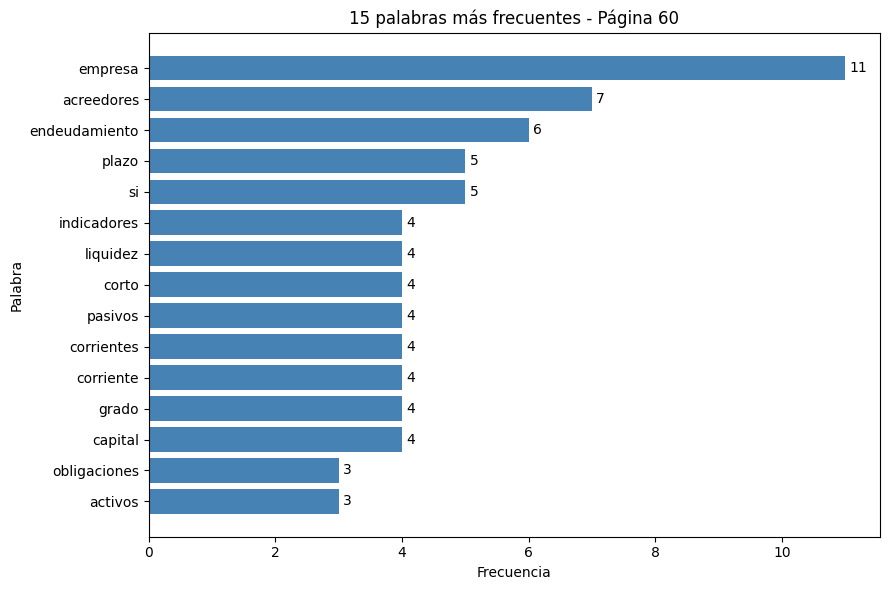

In [27]:
frecuencias = Counter(tokens_limpios)
top15 = frecuencias.most_common(15)

# Tabla con las 15 palabras más frecuentes
tabla_top15 = pd.DataFrame(top15, columns=["Palabra", "Frecuencia"])
print(tabla_top15.to_string(index=False))

# Gráfico de barras horizontales (la más frecuente arriba)
palabras = [p for p, _ in top15][::-1]
cantidades = [c for _, c in top15][::-1]

plt.figure(figsize=(9, 6))
barras = plt.barh(palabras, cantidades, color="steelblue")
plt.bar_label(barras, padding=3)  # muestra el valor al final de cada barra
plt.title(f"15 palabras más frecuentes - Página {PAGINA_TEXTO}")
plt.xlabel("Frecuencia")
plt.ylabel("Palabra")
plt.tight_layout()
plt.show()

# ### ¿Aparecieron tokens que también serían stop words?
# *(Mirar el gráfico y la tabla de arriba y responder con lo que se observe. Preguntas guía:)*
#
# - ¿Hay palabras funcionales que la lista de NLTK **no** eliminó (por ejemplo conjunciones, adverbios o verbos muy comunes)? Justificar por qué no aportan significado al tema.
# - ¿Hay palabras que son muy frecuentes pero propias del dominio (por ejemplo, el tema general del texto)? ¿Conviene quitarlas o son justamente las que describen el texto?
# - ¿Se repiten palabras en singular y plural o en distintas formas (empresa/empresas, corriente/corrientes)? ¿Qué efecto tiene eso en el conteo?
# - Algo a tener en cuenta: si varias palabras empatan en el puesto 15, el corte del "top 15" es arbitrario.

Top 15 con la lista ampliada:
      Palabra  Frecuencia
      empresa          11
   acreedores           7
endeudamiento           6
        plazo           5
  indicadores           4
     liquidez           4
        corto           4
      pasivos           4
   corrientes           4
    corriente           4
        grado           4
      capital           4
 obligaciones           3
      activos           3
    capacidad           3


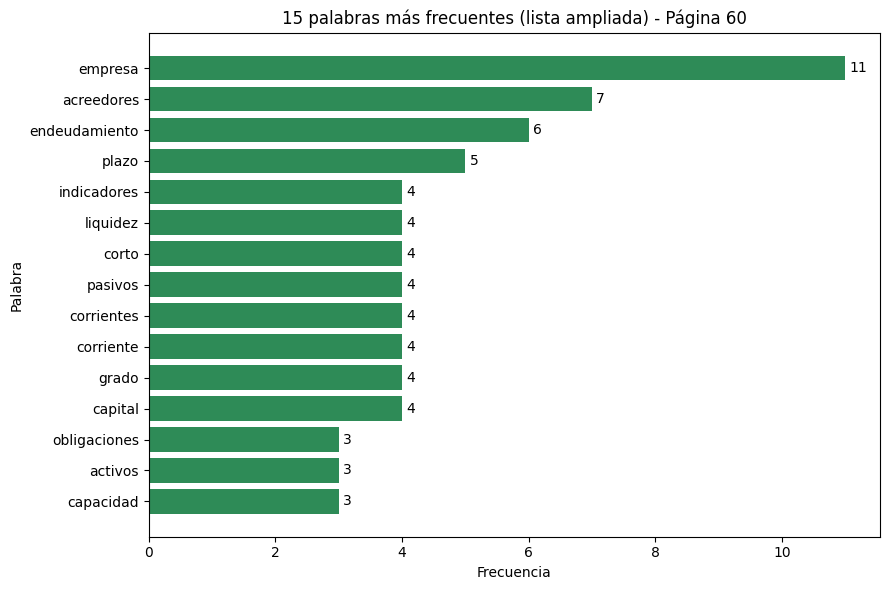

In [28]:
STOP_WORDS_ADICIONALES = {"si"}

stop_words_ampliada = stop_words_es | STOP_WORDS_ADICIONALES
tokens_limpios_2 = [t for t in solo_palabras if t not in stop_words_ampliada]
top15_2 = Counter(tokens_limpios_2).most_common(15)

print("Top 15 con la lista ampliada:")
print(pd.DataFrame(top15_2, columns=["Palabra", "Frecuencia"]).to_string(index=False))

# Gráfico de comparación
palabras_2 = [p for p, _ in top15_2][::-1]
cantidades_2 = [c for _, c in top15_2][::-1]

plt.figure(figsize=(9, 6))
barras = plt.barh(palabras_2, cantidades_2, color="seagreen")
plt.bar_label(barras, padding=3)
plt.title(f"15 palabras más frecuentes (lista ampliada) - Página {PAGINA_TEXTO}")
plt.xlabel("Frecuencia")
plt.ylabel("Palabra")
plt.tight_layout()
plt.show()